# Do Democrats and Republicans Talk About the Same Issues Differently?

**Topic modeling (LDA) + party-specific word embeddings (Word2Vec) on U.S. House floor speeches**

Originally written for UC Berkeley INFO 159/259 (Natural Language Processing), Homework 6: Unsupervised Methods. This version fixes several pipeline bugs found in the original submission and extends the analysis. See the README for details.

**Questions**
1. What issues dominate this set of congressional speeches?
2. Given the same issue, do the two parties surround it with different vocabulary?

## 1. Data

The data is a subset of the [Congressional Speech (Convote) corpus](https://www.cs.cornell.edu/home/llee/data/convote.html) (Thomas, Pang & Lee, 2006): floor-debate speeches from the U.S. House of Representatives, labeled by the speaker's party. The text is already lowercased and tokenized. Each non-empty line of a file is one speech.

In [1]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from gensim.models import Word2Vec

SEED = 0
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DEM_COLOR, REP_COLOR = "#2b6cb0", "#c53030"

def load_speeches(path):
    with open(path) as f:
        return [line.strip() for line in f if line.strip()]

dem = load_speeches("democrat_speeches.txt")
rep = load_speeches("republican_speeches.txt")
speeches = dem + rep
party = np.array([0] * len(dem) + [1] * len(rep))   # 0 = Democrat, 1 = Republican

lengths = np.array([len(s.split()) for s in speeches])
print(f"Democratic speeches: {len(dem)}   Republican speeches: {len(rep)}")
print(f"Words per speech: median {int(np.median(lengths))}, mean {lengths.mean():.0f}, max {lengths.max()}")

Democratic speeches: 168   Republican speeches: 199
Words per speech: median 429, mean 564, max 6830


## 2. Topic modeling with LDA

**Preprocessing.** Each speech is one document. I use raw word counts rather than TF-IDF, because LDA is a generative model of counts. I drop English stopwords, procedural boilerplate ("mr. speaker", "yield", "gentleman"), tokens shorter than three letters, words in fewer than 5 speeches, and words in more than half of all speeches.

**Choosing the number of topics.** I keep *k = 5*, as in the original assignment. This is a readability choice, not a tuned one. Section 5 discusses it.

In [2]:
PROCEDURAL = {
    "mr", "speaker", "gentleman", "gentlewoman", "gentlemen", "madam", "yield", "chairman",
    "rise", "thank", "thanks", "today", "time", "minority", "majority", "member", "members",
    "house", "congress", "bill", "legislation", "vote", "year", "years", "new", "people",
    "say", "just", "going", "would", "could", "also", "want", "think", "know", "make",
    "let", "like", "way", "need",
}
STOPWORDS = list(ENGLISH_STOP_WORDS | PROCEDURAL)

vectorizer = CountVectorizer(stop_words=STOPWORDS, token_pattern=r"\b[a-z]{3,}\b", min_df=5, max_df=0.5)
X = vectorizer.fit_transform(speeches)
vocab = vectorizer.get_feature_names_out()
print(f"Document-term matrix: {X.shape[0]} speeches x {X.shape[1]} terms")

K = 5
lda = LatentDirichletAllocation(n_components=K, learning_method="batch", max_iter=50, random_state=SEED)
theta = lda.fit_transform(X)    # speech-by-topic proportions

for k, weights in enumerate(lda.components_):
    top = vocab[weights.argsort()[::-1][:12]]
    print(f"Topic {k}: {', '.join(top)}")

Document-term matrix: 367 speeches x 2532 terms


Topic 0: health, small, insurance, pension, million, care, percent, budget, employees, plans, businesses, americans
Topic 1: law, states, security, state, committee, federal, provisions, immigration, driver, bankruptcy, border, asylum
Topic 2: energy, oil, gas, percent, companies, national, policy, prices, nation, gasoline, price, foreign
Topic 3: gang, united, federal, children, state, states, law, lawsuits, trade, food, enforcement, police
Topic 4: osha, tax, small, american, workers, safety, business, commission, work, jobs, businesses, families


### Naming the topics

These labels are my own reading of the top words. They are interpretations, not model output.

| Topic | Label | Top words |
|---|---|---|
| 0 | Health care and pensions | health, small, insurance, pension, care, plans |
| 1 | Immigration and federal law | law, states, security, immigration, driver, bankruptcy, border, asylum |
| 2 | Energy and prices | energy, oil, gas, companies, prices, gasoline |
| 3 | Crime, trade and enforcement | gang, federal, children, law, lawsuits, trade, police |
| 4 | Workplace safety, taxes and jobs | osha, tax, small, workers, safety, jobs, families |

Topic 3 is the least clean: it combines gang legislation, lawsuit reform and trade. That is a sign that *k = 5* is a bit too coarse for this corpus.

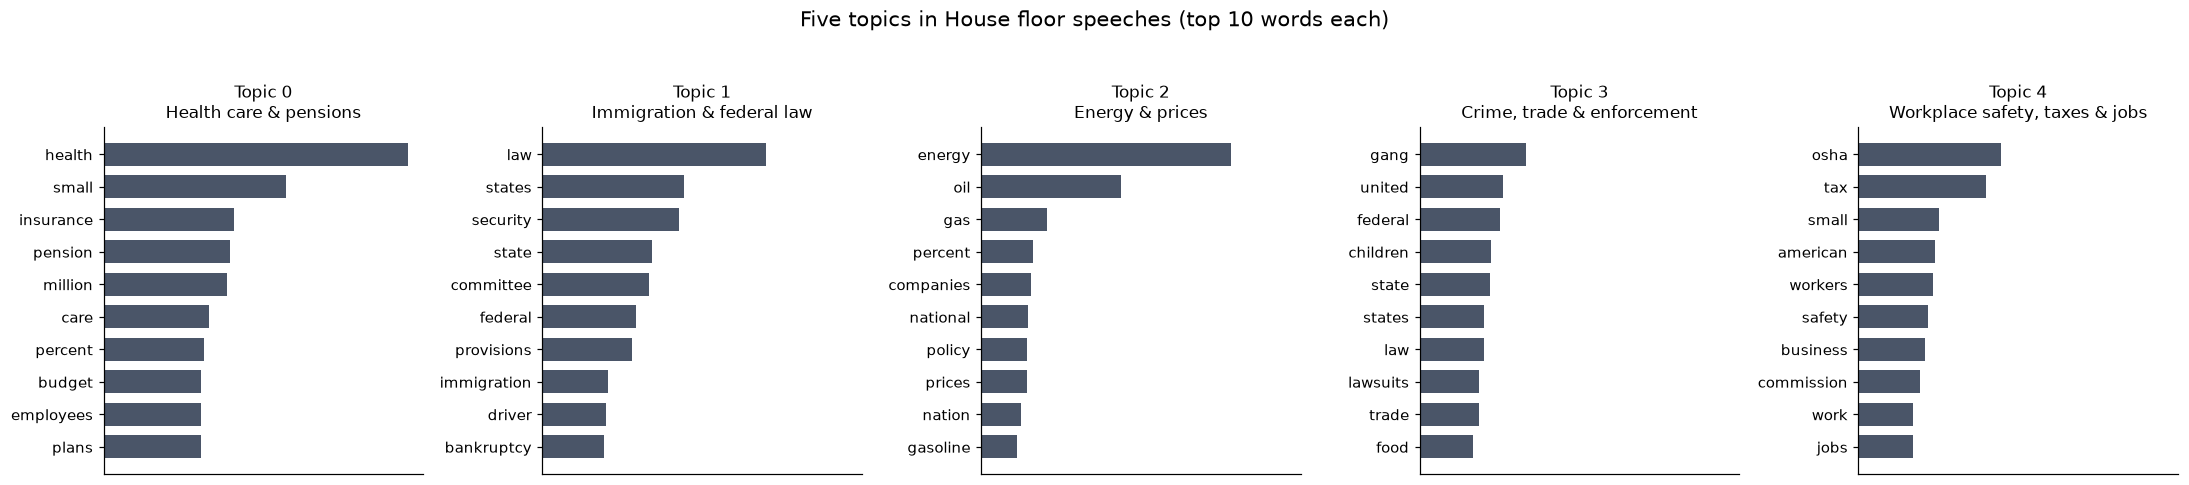

In [3]:
TOPIC_LABELS = [
    "Health care & pensions",
    "Immigration & federal law",
    "Energy & prices",
    "Crime, trade & enforcement",
    "Workplace safety, taxes & jobs",
]

fig, axes = plt.subplots(1, K, figsize=(20, 4.2), sharex=True)
for k, ax in enumerate(axes):
    idx = lda.components_[k].argsort()[-10:]
    ax.barh(vocab[idx], lda.components_[k][idx], color="#4a5568", height=0.7)
    ax.set_title(f"Topic {k}\n{TOPIC_LABELS[k]}", fontsize=11)
    ax.tick_params(axis="y", labelsize=10)
    ax.set_xticks([])
fig.suptitle("Five topics in House floor speeches (top 10 words each)", fontsize=14, y=1.04)
fig.tight_layout()
fig.savefig("figures/topics.png", bbox_inches="tight")
plt.show()

### Do the parties emphasize different topics?

For each topic I compare the average topic share in Democratic and Republican speeches. To show whether the gap is larger than sampling noise, I bootstrap speeches (2,000 resamples) and plot a 95% interval on the difference.

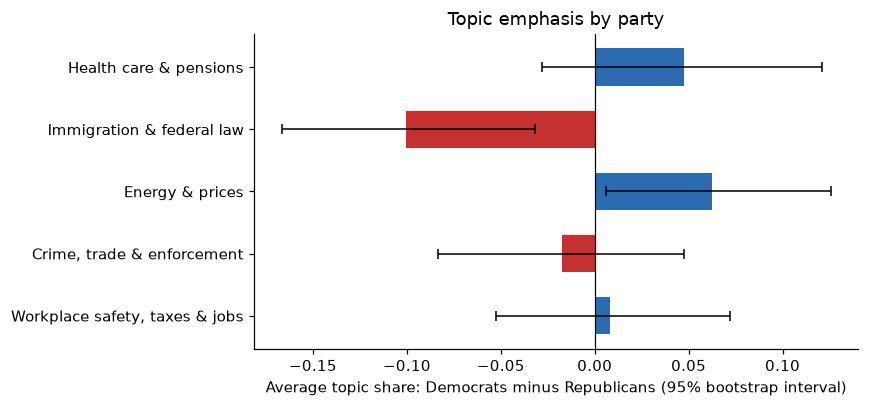

Topic 0 (Health care & pensions): D 0.27 vs R 0.22, diff +0.05 [-0.03, +0.12] (includes 0)
Topic 1 (Immigration & federal law): D 0.17 vs R 0.27, diff -0.10 [-0.17, -0.03] (excludes 0)
Topic 2 (Energy & prices): D 0.16 vs R 0.10, diff +0.06 [+0.01, +0.13] (excludes 0)
Topic 3 (Crime, trade & enforcement): D 0.19 vs R 0.21, diff -0.02 [-0.08, +0.05] (includes 0)
Topic 4 (Workplace safety, taxes & jobs): D 0.21 vs R 0.20, diff +0.01 [-0.05, +0.07] (includes 0)


In [4]:
rng = np.random.default_rng(SEED)
dem_theta, rep_theta = theta[party == 0], theta[party == 1]
diff = dem_theta.mean(0) - rep_theta.mean(0)

boot = np.empty((2000, K))
for b in range(2000):
    d = dem_theta[rng.integers(0, len(dem_theta), len(dem_theta))].mean(0)
    r = rep_theta[rng.integers(0, len(rep_theta), len(rep_theta))].mean(0)
    boot[b] = d - r
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(K)
colors = [DEM_COLOR if d > 0 else REP_COLOR for d in diff]
ax.barh(y, diff, color=colors, height=0.6)
ax.errorbar(diff, y, xerr=[diff - lo, hi - diff], fmt="none", ecolor="black", capsize=3, lw=1)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y, TOPIC_LABELS)
ax.invert_yaxis()
ax.set_xlabel("Average topic share: Democrats minus Republicans (95% bootstrap interval)")
ax.set_title("Topic emphasis by party")
fig.tight_layout()
fig.savefig("figures/topic_share_by_party.png", bbox_inches="tight")
plt.show()

for k in range(K):
    sig = "excludes 0" if (lo[k] > 0 or hi[k] < 0) else "includes 0"
    print(f"Topic {k} ({TOPIC_LABELS[k]}): D {dem_theta[:, k].mean():.2f} vs R {rep_theta[:, k].mean():.2f}, "
          f"diff {diff[k]:+.2f} [{lo[k]:+.2f}, {hi[k]:+.2f}] ({sig})")

## 3. Party-specific word embeddings (Word2Vec)

**Idea.** Train one Word2Vec model on Democratic speeches and one on Republican speeches. For a seed word such as *energy*, the nearest neighbors in each model show which words each party uses in the same contexts.

**Choices that matter here**
- **Sentence-level training.** Speeches are split on `" . "` so the context window never crosses sentence boundaries.
- **Skip-gram, 30 epochs, `min_count=5`.** Each party has only about 45,000 tokens after stopword removal. That is very small for embeddings, so I use skip-gram, which handles small corpora better, and train for many epochs.
- **Stability filter.** With a corpus this small, neighbors can change with the random seed. I train each model with 5 seeds and keep only neighbors that appear in the top 10 for **all 5**. These are the findings I trust.
- **Seed words.** I hand-picked two high-weight words per topic (below). This is a subjective choice. The neighbors of a *pair* of words are the neighbors of their average vector.

In [5]:
def to_sentences(speech_list):
    sentences = []
    for speech in speech_list:
        for sent in speech.split(" . "):
            tokens = [w for w in re.findall(r"\b[a-z]{2,}\b", sent) if w not in ENGLISH_STOP_WORDS]
            if len(tokens) > 2:
                sentences.append(tokens)
    return sentences

sent_dem, sent_rep = to_sentences(dem), to_sentences(rep)
print(f"Democrats: {len(sent_dem):,} sentences, {sum(map(len, sent_dem)):,} tokens")
print(f"Republicans: {len(sent_rep):,} sentences, {sum(map(len, sent_rep)):,} tokens")

SEEDS = {
    "Health care": ["health", "insurance"],
    "Immigration": ["immigration", "border"],
    "Energy": ["energy", "oil"],
    "Crime & enforcement": ["gang", "police"],
    "Taxes & jobs": ["tax", "workers"],
}
N_SEEDS, TOPN = 5, 10

def stable_neighbors(sentences, seed_words):
    runs = []
    for s in range(N_SEEDS):
        model = Word2Vec(sentences, vector_size=100, window=5, min_count=5, sg=1,
                         epochs=30, seed=s, workers=1)
        runs.append([w for w, _ in model.wv.most_similar(seed_words, topn=TOPN)])
    # keep the order from the first run, restricted to words present in every run
    return [w for w in runs[0] if all(w in r for r in runs)]

results = {}
for topic, words in SEEDS.items():
    results[topic] = {
        "Democrats": stable_neighbors(sent_dem, words),
        "Republicans": stable_neighbors(sent_rep, words),
    }
    print(f"\n{topic}  (seeds: {', '.join(words)})")
    print("  Democrats:  ", ", ".join(results[topic]["Democrats"]))
    print("  Republicans:", ", ".join(results[topic]["Republicans"]))

Democrats: 4,054 sentences, 47,036 tokens
Republicans: 3,695 sentences, 43,242 tokens



Health care  (seeds: health, insurance)
  Democrats:   coverage, opponents, preventive, drop, cherry, options
  Republicans: coverage, care, premiums, bargaining, quality, ahps, enjoy, ahp, afford



Immigration  (seeds: immigration, border)
  Democrats:   detention, patrol, agents, carefully, borders, homeland, broadly
  Republicans: roads, illegal, patrol, gaps, agents, san



Energy  (seeds: energy, oil)
  Democrats:   reliance, decrease, fossil, dependence, sources, imports
  Republicans: dependence, capacity, exploration, reliance, production, refining, conservation, promotes



Crime & enforcement  (seeds: gang, police)
  Democrats:   mcguire, ret, maine, dept, lemongello, foundation
  Republicans: sheriffs, investigators, deterrence, writing, troopers, networks, violence, los, angeles, gangs



Taxes & jobs  (seeds: tax, workers)
  Democrats:   richest, reconciliation, extend, wealthy, gains, break, raises
  Republicans: seniors, extension, hire, earned, succeed, retirement


## 4. Which words separate the parties overall?

As a count-based cross-check on the embeddings, I compute smoothed **log-odds ratios** of each word's frequency in Democratic versus Republican speeches, restricted to words that appear at least 30 times. Positive values lean Democratic and negative values lean Republican. This does not depend on embedding quality.

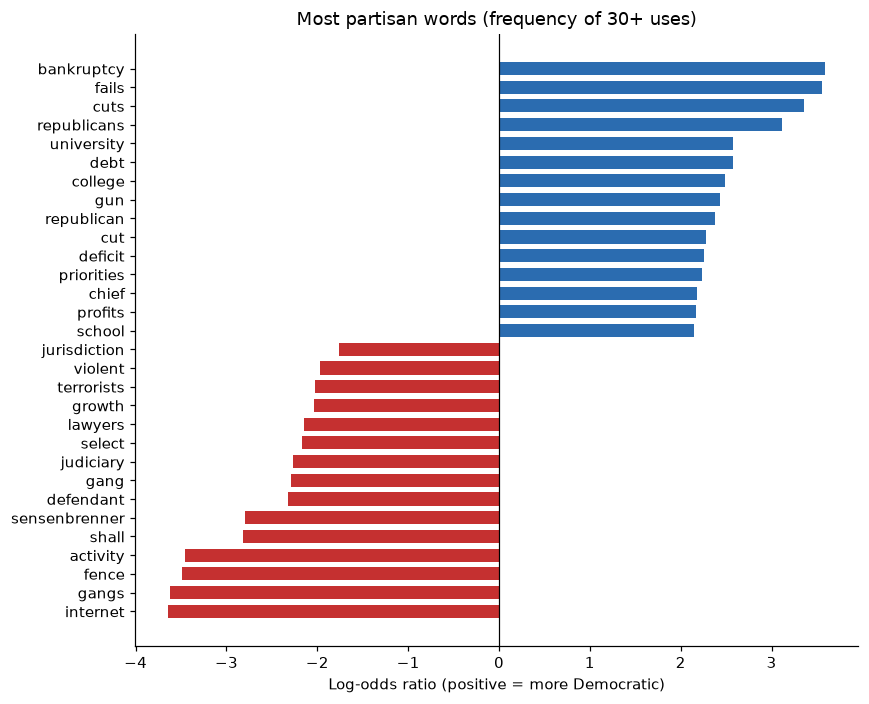

Republican-leaning: internet, gangs, fence, activity, shall, sensenbrenner, defendant, gang, judiciary, select, lawyers, growth, terrorists, violent, jurisdiction
Democratic-leaning: bankruptcy, fails, cuts, republicans, university, debt, college, gun, republican, cut, deficit, priorities, chief, profits, school


In [6]:
counts = np.asarray(X.todense())
d_counts = counts[party == 0].sum(0) + 0.01
r_counts = counts[party == 1].sum(0) + 0.01
log_odds = np.log(d_counts / d_counts.sum()) - np.log(r_counts / r_counts.sum())

frequent = np.where(counts.sum(0) >= 30)[0]
order = frequent[np.argsort(log_odds[frequent])]
top_rep, top_dem = order[:15], order[::-1][:15]

fig, ax = plt.subplots(figsize=(8, 6.5))
idx = np.concatenate([top_rep, top_dem[::-1]])
ax.barh(vocab[idx], log_odds[idx], color=[REP_COLOR] * 15 + [DEM_COLOR] * 15, height=0.7)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Log-odds ratio (positive = more Democratic)")
ax.set_title("Most partisan words (frequency of 30+ uses)")
fig.tight_layout()
fig.savefig("figures/partisan_words.png", bbox_inches="tight")
plt.show()
print("Republican-leaning:", ", ".join(vocab[top_rep]))
print("Democratic-leaning:", ", ".join(vocab[top_dem]))

## 5. Findings

**Topics.** LDA recovers five readable issue clusters: health care and pensions, immigration and federal law, energy and prices, crime and trade, and workplace safety and taxes. Only two party gaps are distinguishable from sampling noise (95% bootstrap interval excludes 0): Republican speeches give more weight to **immigration and federal law** (27% vs 17%), and Democratic speeches give more weight to **energy and prices** (16% vs 10%). The health care, crime and workplace/tax gaps are small and their intervals include 0.

**Embeddings.** Where the stable neighbors are informative, they show different framing of the same issue. On **energy**, the parties share *dependence* and *reliance*, but the Democratic neighbors add *fossil, imports, sources, decrease*, while the Republican neighbors add *production, exploration, refining, capacity*. That reads as reducing reliance versus increasing supply. On **taxes and jobs**, Democratic speeches sit near *wealthy, richest, gains, raises*, and Republican speeches sit near *seniors, retirement, hire, extension*. On **immigration**, both parties share *patrol* and *agents*, but Republican neighbors add *illegal, gaps*, while Democratic neighbors add *detention, homeland*. The **crime** result is not usable for Democrats: their neighbors (*mcguire, ret, maine, lemongello*) are names and titles from quoted letters, not policy language.

**Overall vocabulary.** Democratic speeches lean toward budget and education words (*cuts, deficit, college, school, priorities*) and name the other party (*republicans*). Republican speeches lean toward law-and-order words (*gangs, defendant, judiciary, terrorists, violent*). Some of this is bill-specific. For example, *bankruptcy* (Democratic) and *sensenbrenner* (Republican, a committee chair's name) reflect particular debates, not party style in general.

## 6. Limitations

- **Small corpus.** There are 367 speeches and roughly 45,000 tokens per party after filtering. Embeddings from this much text are noisy, which is why I report only neighbors that are stable across 5 seeds. Some neighborhoods are dominated by artifacts, such as names and titles from letters quoted in speeches.
- **One debate period.** The speeches come from a limited set of floor debates, so topics reflect those specific bills (for example bankruptcy reform and gang legislation), not Congress in general.
- **Hand-chosen choices.** *k = 5*, the topic labels, the seed words, and the procedural stopword list are all my judgment. I did not tune *k* using coherence or held-out perplexity, and different choices would give somewhat different results.
- **Descriptive only.** These are associations in word usage. They do not show intent, and no significance testing was done on the embedding neighbors.
- **Speech is not just party.** Speaker, committee, and the bill under debate all affect vocabulary, and the party label is confounded with them.

## 7. Ideas for extending this

- Choose *k* with topic coherence and compare 5 to 15 topics.
- Use pretrained or contextual embeddings (for example BERT) and compare neighbors against the party-specific models, which would avoid the small-corpus problem.
- Train a party classifier and inspect its most predictive features as a supervised counterpart to the log-odds analysis.